In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display

simulator = AerSimulator()

print("Libraries imported successfully!")

Libraries imported successfully!


## Experiment 1: Original Bell-State Circuit

### Prediction Before Execution

The circuit starts with both qubits in state |00⟩. The H gate creates a superposition on the first qubit, and the CNOT gate entangles the two qubits. I predict that measurement outcomes `00` and `11` will occur, with approximately equal probabilities. The qubits should produce matching outcomes.

In [2]:
bell_circuit = QuantumCircuit(2, 2)
bell_circuit.h(0)
bell_circuit.cx(0, 1)
bell_circuit.measure([0, 1], [0, 1])
print(bell_circuit.draw(output="text"))

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


In [3]:
compiled_bell = transpile(bell_circuit, simulator)

result_bell = simulator.run(
    compiled_bell,
    shots=100
).result()

counts_bell = result_bell.get_counts()

print("Original Bell-state results:", counts_bell)
print("Total shots:", sum(counts_bell.values()))

Original Bell-state results: {'00': 54, '11': 46}
Total shots: 100


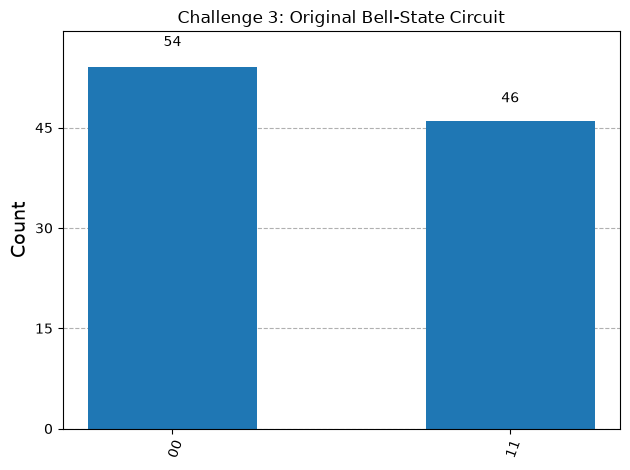

In [4]:
fig = plot_histogram(
    counts_bell,
    title="Challenge 3: Original Bell-State Circuit"
)

display(fig)

## Experiment 2: Modified Bell-State Circuit

### Prediction Before Execution

I will modify the original Bell-state circuit by adding an X gate to qubit 1. This flips the second qubit while preserving the correlation structure of the Bell state. I predict that outcomes `01` and `10` will occur, and the two qubits will produce opposite measurement outcomes.

In [5]:
modified_circuit = QuantumCircuit(2, 2)

modified_circuit.h(0)
modified_circuit.cx(0, 1)
modified_circuit.x(1)
modified_circuit.measure([0, 1], [0, 1])

print(modified_circuit.draw(output="text"))

     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 


In [6]:
compiled_modified = transpile(modified_circuit, simulator)

result_modified = simulator.run(
    compiled_modified,
    shots=100
).result()

counts_modified = result_modified.get_counts()

print("Modified circuit results:", counts_modified)
print("Total shots:", sum(counts_modified.values()))

Modified circuit results: {'01': 55, '10': 45}
Total shots: 100


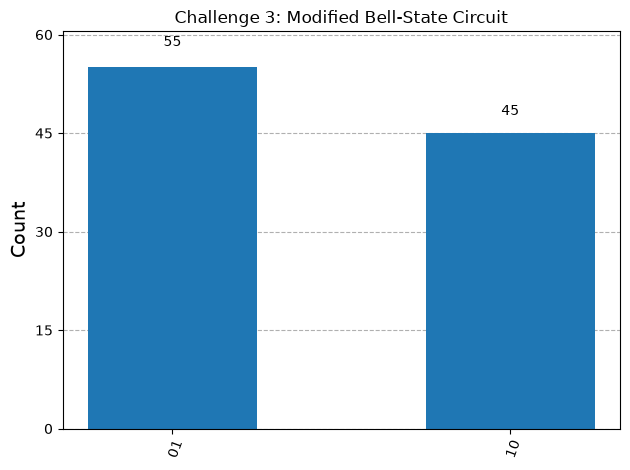

In [7]:
fig = plot_histogram(
    counts_modified,
    title="Challenge 3: Modified Bell-State Circuit"
)

display(fig)

## Comparison of Original and Modified Circuits

| Feature | Original Circuit | Modified Circuit |
|---|---|---|
| Number of qubits | 2 | 2 |
| Gates before measurement | H and CNOT | H, CNOT and X |
| Number of shots | 100 | 100 |
| Expected outcomes | `00` and `11` | `01` and `10` |
| Actual measurement results | `{'00': 54, '11': 46}` | `{'01': 55, '10': 45}` |
| Relationship | Matching outcomes | Opposite outcomes |

## Conclusion

This experiment demonstrated how modifying a quantum circuit can change the relationship between two qubits' measurement outcomes. The original Bell-state circuit produces matching outcomes, while applying an X gate to the second qubit changes the outcomes to opposite pairs. The measurement counts and histograms illustrate this change in correlation.